# Chapitre 2 - Cours 4 : graphes de propriétés, Cypher et requêtes récursives en SQL

Le modèle document convient aux arbres, le relationnel aux relations plusieurs-à-un et
aux plusieurs-à-plusieurs simples. Quand **tout peut être relié à tout**, il devient
plus naturel de penser en **graphe**. Ce cours couvre la section *Graph-Like Data Models*
et ses sous-sections *Property Graphs*, *The Cypher Query Language* et *Graph Queries in
SQL*.

**Plan.**

1. Pourquoi des graphes ? Exemples, représentations, algorithmes.
2. Le graphe de propriétés.
3. Interroger par motifs : le langage Cypher.
4. Les requêtes de graphe en SQL : `WITH RECURSIVE`.

In [1]:
import json
import sqlite3
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import datamodels as dm
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 100)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## 1. Pourquoi des graphes ? (section *Graph-Like Data Models*)

Un graphe a deux sortes d'objets : des **sommets** (nœuds, entités) et des **arêtes**
(relations, arcs). Beaucoup de données s'y prêtent :

- **graphes sociaux** : les sommets sont des personnes, les arêtes disent qui connaît qui ;
- **graphe du Web** : les sommets sont des pages, les arêtes des liens HTML ;
- **réseaux routiers ou ferrés** : les sommets sont des carrefours, les arêtes des
  tronçons.

Des algorithmes classiques opèrent sur ces graphes : le **plus court chemin** pour la
navigation routière, **PageRank** pour estimer la popularité d'une page web et classer
les résultats d'un moteur de recherche.

**Deux représentations.** La **liste d'adjacence** stocke pour chaque sommet les
identifiants de ses voisins ; la **matrice d'adjacence** est un tableau carré dont la
case $(i, j)$ vaut 1 s'il existe une arête de $i$ vers $j$. Pour un graphe de $n$
sommets et $m$ arêtes, la liste occupe $O(n + m)$ et la matrice $O(n^2)$ : les graphes
réels étant très **creux** (chacun n'a que quelques voisins), la liste est bien plus
compacte et permet de parcourir les voisins d'un sommet en temps proportionnel à son
degré.

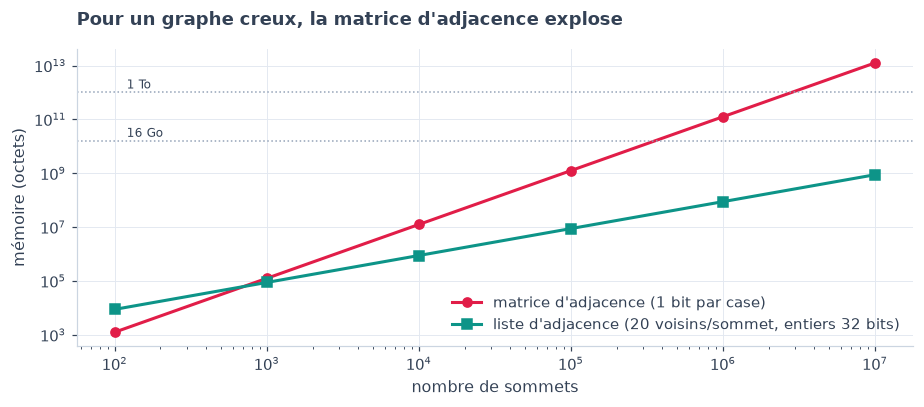

In [2]:
ns = np.array([1e2, 1e3, 1e4, 1e5, 1e6, 1e7])
deg = 20
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.loglog(ns, ns * ns / 8, marker="o", color=ROSE, label="matrice d'adjacence (1 bit par case)")
ax.loglog(ns, ns * 8 + ns * deg * 4, marker="s", color=TEAL, label=f"liste d'adjacence ({deg} voisins/sommet, entiers 32 bits)")
for y, txt in [(16e9, "16 Go"), (1e12, "1 To")]:
    ax.axhline(y, color=GRAY, ls=":", lw=1); ax.text(120, y * 1.4, txt, fontsize=8, color=SLATE)
ax.set_xlabel("nombre de sommets"); ax.set_ylabel("mémoire (octets)")
ax.set_title("Pour un graphe creux, la matrice d'adjacence explose")
ax.legend(); plt.tight_layout(); plt.show()

Illustrons un algorithme de graphe sur une liste d'adjacence : **PageRank** par
itération de puissance sur un petit graphe du Web synthétique (les pages populaires
reçoivent plus de liens). Le score d'une page est la probabilité qu'un internaute qui
clique au hasard (et repart parfois d'une page quelconque, avec probabilité 15 %) s'y
trouve.

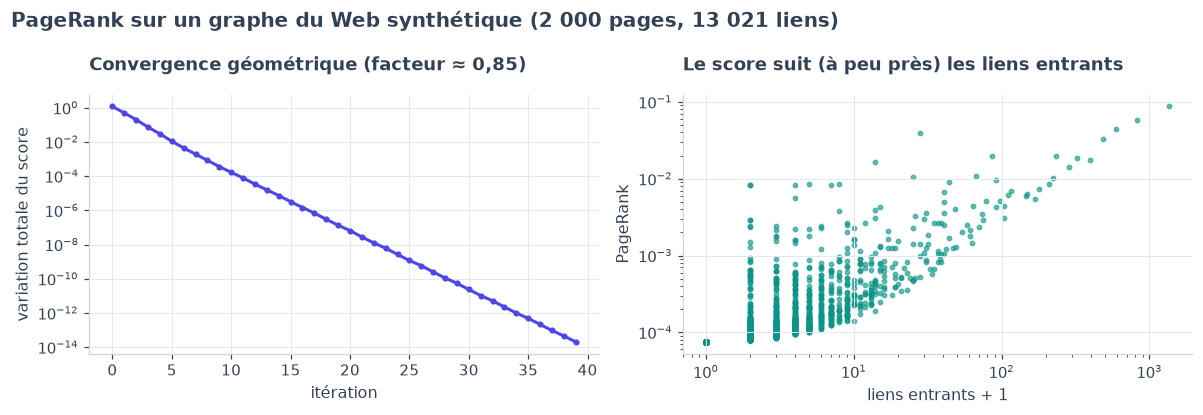

In [3]:
n_pages = 2000
pop = 1 / np.arange(1, n_pages + 1) ** 1.1
pop /= pop.sum()
liens = {p: set(rng.choice(n_pages, size=int(rng.integers(1, 15)), p=pop).tolist()) - {p} for p in range(n_pages)}

def pagerank(adj, n, d=0.85, iters=40):
    pr = np.full(n, 1 / n)
    hist = []
    for _ in range(iters):
        new = np.full(n, (1 - d) / n)
        for u, vs in adj.items():
            if vs:
                share = d * pr[u] / len(vs)
                for v in vs:
                    new[v] += share
            else:
                new += d * pr[u] / n
        hist.append(np.abs(new - pr).sum())
        pr = new
    return pr, hist

pr, hist = pagerank(liens, n_pages)
entrants = np.zeros(n_pages)
for u, vs in liens.items():
    for v in vs:
        entrants[v] += 1
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].semilogy(hist, color=INDIGO, marker=".")
axes[0].set_xlabel("itération"); axes[0].set_ylabel("variation totale du score")
axes[0].set_title("Convergence géométrique (facteur ≈ 0,85)")
axes[1].scatter(entrants + 1, pr, s=8, color=TEAL, alpha=0.6)
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("liens entrants + 1"); axes[1].set_ylabel("PageRank")
axes[1].set_title("Le score suit (à peu près) les liens entrants")
finish(fig, f"PageRank sur un graphe du Web synthétique ({fmt(n_pages)} pages, {fmt(sum(map(len, liens.values())))} liens)")

Les exemples ci-dessus sont **homogènes** (tous les sommets sont du même type). Un usage
tout aussi puissant des graphes est de ranger des objets **de types différents** dans une
même base. Facebook entretient ainsi un graphe unique dont les sommets sont des
personnes, des lieux, des événements, des commentaires, et dont les arêtes disent qui est
ami avec qui, quel commentaire porte sur quel message, qui a participé à quel
événement.

> **À retenir.** Un graphe, ce sont des sommets et des arêtes. La liste d'adjacence
> ($O(n + m)$) convient aux graphes creux et aux parcours ; la matrice ($O(n^2)$) aux
> calculs algébriques. Un graphe peut mêler des sommets et des arêtes de types variés.

## 2. Le graphe de propriétés (section *Property Graphs*)

Dans le modèle du **graphe de propriétés** (Neo4j et
d'autres, comme Titan ou InfiniteGraph), chaque **sommet** a un identifiant unique,
un **label** (son type), ses arêtes sortantes et entrantes, et des **propriétés**
(paires clé-valeur). Chaque **arête** a un identifiant, un sommet de départ (la *queue*),
un sommet d'arrivée (la *tête*), un label qui décrit la relation et ses propres
propriétés.

Notre exemple fil rouge (`dm.example_graph`) rassemble trois personnes et des lieux
emboîtés : Inès, née à Lyon, et Kenji, né à Osaka, sont mariés et vivent à Montréal ;
Léa, née en Bretagne, vit à Lyon.

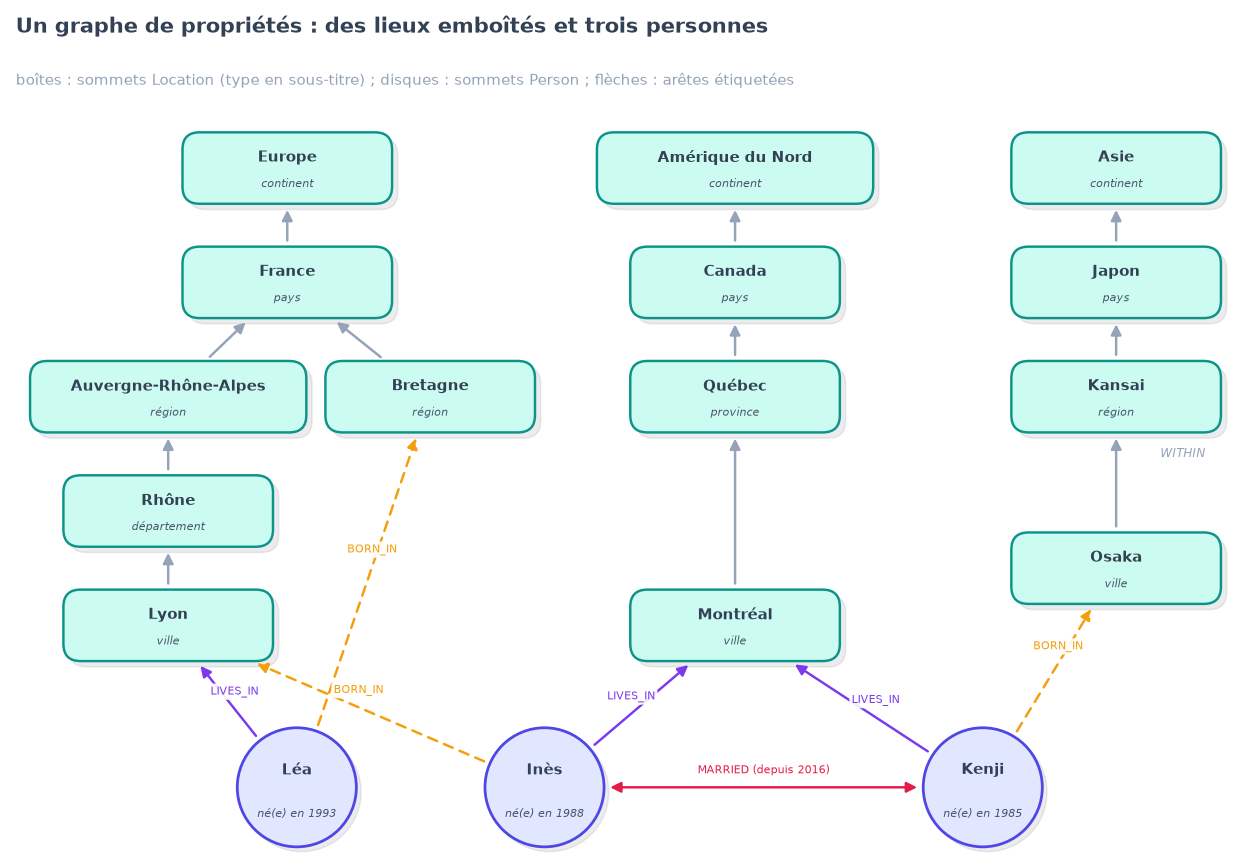

In [4]:
g = dm.example_graph()
pos = {"europe": (2.9, 7.2), "amnord": (7.6, 7.2), "asie": (11.6, 7.2),
       "france": (2.9, 6.0), "canada": (7.6, 6.0), "japon": (11.6, 6.0),
       "aura": (1.65, 4.8), "bretagne": (4.4, 4.8), "quebec": (7.6, 4.8), "kansai": (11.6, 4.8),
       "rhone": (1.65, 3.6), "lyon": (1.65, 2.4), "montreal": (7.6, 2.4), "osaka": (11.6, 3.0),
       "lea": (3.0, 0.7), "ines": (5.6, 0.7), "kenji": (10.2, 0.7)}
d = Diagram(13, 7.9, title="Un graphe de propriétés : des lieux emboîtés et trois personnes",
            subtitle="boîtes : sommets Location (type en sous-titre) ; disques : sommets Person ; flèches : arêtes étiquetées")
for v, (x, y) in pos.items():
    lab, p = g.vertices[v]
    if lab == "Person":
        d.box(v, x, y, p["name"], sub=f"né(e) en {p['birth_year']}", kind="user", w=1.25, color=INDIGO, fontsize=9.5)
    else:
        d.box(v, x, y, p["name"], sub=p["type"], w=2.2 if len(p["name"]) < 14 else 2.9, h=0.75, color=TEAL, fontsize=9.5)
style = {"WITHIN": (GRAY, "solid"), "BORN_IN": (AMBER, "dashed"), "LIVES_IN": (VIOLET, "solid")}
for _, t, h, lab, _p in g.edges:
    if lab == "MARRIED":
        continue
    col, ls = style[lab]
    d.arrow(t, h, None if lab == "WITHIN" else lab, color=col, style=ls, fontsize=7.5,
            label_pos=0.55 if lab == "BORN_IN" else 0.4)
d.arrow("ines", "kenji", "MARRIED (depuis 2016)", color=ROSE, both=True, fontsize=7.5)
d.note(12.3, 4.2, "WITHIN", color=GRAY, fontsize=8)
d.show()

Le graphe montre ce qui serait pénible dans un schéma relationnel classique :
des **structures régionales différentes** selon les pays (régions et départements en
France, provinces au Canada, régions au Japon), et une **granularité variable** (Inès est
née dans une ville, Léa seulement dans une région).

On peut voir un graphe de propriétés comme **deux tables relationnelles**, une pour les
sommets et une pour les arêtes, avec les propriétés en JSON et un index sur chaque
extrémité des arêtes pour parcourir le graphe dans les deux sens. C'est ce que fait
`PropertyGraph.to_sqlite`.

In [5]:
con = sqlite3.connect(":memory:")
g.to_sqlite(con)
print(con.execute("SELECT sql FROM sqlite_master WHERE name = 'edges'").fetchone()[0])
pd.read_sql("""SELECT e.edge_id, t.properties ->> 'name' AS queue, e.label, h.properties ->> 'name' AS tête
                 FROM edges e JOIN vertices t ON t.vertex_id = e.tail_vertex
                              JOIN vertices h ON h.vertex_id = e.head_vertex
                WHERE e.label != 'WITHIN'""", con)

CREATE TABLE edges (edge_id INTEGER PRIMARY KEY,
                            tail_vertex INTEGER REFERENCES vertices (vertex_id),
                            head_vertex INTEGER REFERENCES vertices (vertex_id),
                            label TEXT, properties TEXT)


,edge_id,queue,label,tête
0,11,Inès,BORN_IN,Lyon
1,12,Inès,LIVES_IN,Montréal
2,13,Kenji,BORN_IN,Osaka
3,14,Kenji,LIVES_IN,Montréal
4,15,Léa,BORN_IN,Bretagne
5,16,Léa,LIVES_IN,Lyon
6,17,Inès,MARRIED,Kenji
7,18,Kenji,MARRIED,Inès


Trois propriétés importantes de ce modèle :

- **n'importe quel sommet** peut être relié à n'importe quel autre : aucun schéma ne
  restreint quels types d'objets peuvent être associés ;
- depuis un sommet, on trouve efficacement ses arêtes **entrantes et sortantes** (d'où
  les deux index), et l'on peut parcourir le graphe dans les deux sens ;
- des **labels** différents pour des relations différentes permettent de ranger
  plusieurs sortes d'informations dans un même graphe tout en gardant un modèle propre.

La table `edges` n'est rien d'autre que la **table d'association** du cours 2,
généralisée pour accueillir tous les types de relations à la fois.

**Les graphes sont évolutifs.** Ajoutons à notre graphe des allergies : un sommet par
allergène, une arête `ALLERGIC_TO` entre une personne et un allergène, et des arêtes
`CONTAINS` entre plats et allergènes. Aucune migration : on ajoute des sommets et des
arêtes d'un nouveau type, puis on demande ce que chacun peut manger sans risque.

In [6]:
for a in ["arachide", "gluten", "lactose", "crustacés"]:
    g.add_vertex(a, "Allergen", name=a)
plats = {"pad thaï": ["arachide", "crustacés"], "quiche": ["gluten", "lactose"], "sushi": ["crustacés"],
         "ratatouille": [], "poutine": ["lactose"], "ramen": ["gluten"]}
for p, alls in plats.items():
    g.add_vertex(p, "Dish", name=p)
    for a in alls:
        g.add_edge(p, a, "CONTAINS")
for who, a in [("ines", "arachide"), ("kenji", "lactose"), ("lea", "gluten")]:
    g.add_edge(who, a, "ALLERGIC_TO")

def safe_dishes(person):
    allergies = set(g.out(person, "ALLERGIC_TO"))
    return sorted(g.props(p)["name"] for p in plats if not allergies & set(g.out(p, "CONTAINS")))

pd.DataFrame({"personne": [g.props(p)["name"] for p in ["ines", "kenji", "lea"]],
              "allergies": [", ".join(g.out(p, "ALLERGIC_TO")) for p in ["ines", "kenji", "lea"]],
              "plats sans risque": [", ".join(safe_dishes(p)) for p in ["ines", "kenji", "lea"]]})

,personne,allergies,plats sans risque
0,Inès,arachide,"poutine, quiche, ramen, ratatouille, sushi"
1,Kenji,lactose,"pad thaï, ramen, ratatouille, sushi"
2,Léa,gluten,"pad thaï, poutine, ratatouille, sushi"


> **À retenir.** Un graphe de propriétés, ce sont des sommets et des arêtes étiquetés
> portant des propriétés clé-valeur ; il se range dans deux tables (sommets, arêtes)
> indexées aux deux extrémités. Sans schéma imposé, il s'étend facilement à de nouveaux
> types de relations.

## 3. Interroger par motifs : le langage Cypher (section *The Cypher Query Language*)

**Cypher** est le langage de requête des graphes de propriétés créé pour Neo4j (son nom vient d'un personnage du film *Matrix*, pas de la cryptographie). Il
décrit les arêtes par une notation en **flèches** : `(lyon) -[:WITHIN]-> (rhone)`. Voici
comment on créerait la partie gauche de notre graphe :

```cypher
CREATE
  (europe :Location {name:'Europe',               type:'continent'}),
  (france :Location {name:'France',               type:'pays'}),
  (aura   :Location {name:'Auvergne-Rhône-Alpes', type:'région'}),
  (rhone  :Location {name:'Rhône',                type:'département'}),
  (lyon   :Location {name:'Lyon',                 type:'ville'}),
  (ines   :Person   {name:'Inès'}),
  (lyon) -[:WITHIN]-> (rhone) -[:WITHIN]-> (aura) -[:WITHIN]-> (france) -[:WITHIN]-> (europe),
  (ines) -[:BORN_IN]-> (lyon)
```

Question : **qui est né en Europe et vit en Amérique du Nord ?** En Cypher, on décrit le
motif à trouver ; `-[:WITHIN*0..]->` signifie « suivre zéro, une ou plusieurs arêtes
WITHIN », comme l'étoile d'une expression régulière :

```cypher
MATCH
  (person) -[:BORN_IN]->  () -[:WITHIN*0..]-> (:Location {name:'Europe'}),
  (person) -[:LIVES_IN]-> () -[:WITHIN*0..]-> (:Location {name:'Amérique du Nord'})
RETURN person.name
```

Comme SQL, Cypher est **déclaratif** : le moteur choisit comment exécuter ce motif. Deux
stratégies au moins sont possibles, que notre module implémente :

1. **en avant** (`emigrants_forward`) : parcourir toutes les personnes, et pour chacune
   remonter les arêtes `WITHIN` depuis son lieu de naissance et de résidence ;
2. **en arrière** (`emigrants_backward`) : trouver les deux lieux par un index sur
   `name`, descendre les arêtes `WITHIN` **entrantes** pour collecter tous les lieux
   qu'ils contiennent, puis les personnes qui y sont nées ou y vivent.

In [7]:
c1, c2 = {}, {}
print("en avant  :", dm.emigrants_forward(g, "Europe", "Amérique du Nord", c1), c1)
print("en arrière :", dm.emigrants_backward(g, "Europe", "Amérique du Nord", c2), c2)

en avant  : {'Inès'} {'sommets': 3, 'aretes': 34}
en arrière : {'Inès'} {'sommets': 2, 'aretes': 26}


Sur ce petit graphe, la différence est faible. Passons à un graphe synthétique réaliste
(`dm.make_world_graph`) : 6 continents, 48 pays, 288 régions, 2 880 villes et 50 000
personnes, dont 10 % de lieux renseignés seulement au niveau de la région ou du pays.

In [8]:
world = dm.make_world_graph(n_people=50_000, seed=1)
print(f"{fmt(len(world.vertices))} sommets, {fmt(len(world.edges))} arêtes")
paires = [("Europe", "Amérique du Nord"), ("Océanie", "Europe"), ("Pays 0.3", "Asie"),
          ("Région 4.2.1", "Pays 0.0"), ("Ville 4.0.0.0", "Asie")]
rows = []
for born, lives in paires:
    cf, cb = {}, {}
    t0 = time.perf_counter(); rf = dm.emigrants_forward(world, born, lives, cf); tf = time.perf_counter() - t0
    t0 = time.perf_counter(); rb = dm.emigrants_backward(world, born, lives, cb); tb = time.perf_counter() - t0
    assert rf == rb
    rows.append({"né(e) à": born, "vit à": lives, "résultats": len(rf),
                 "arêtes, en avant": cf["aretes"], "arêtes, en arrière": cb["aretes"],
                 "ms en avant": tf * 1e3, "ms en arrière": tb * 1e3})
strat = pd.DataFrame(rows)
strat

53 222 sommets, 103 216 arêtes


,né(e) à,vit à,résultats,"arêtes, en avant","arêtes, en arrière",ms en avant,ms en arrière
0,Europe,Amérique du Nord,388,298083,70696,107.351,11.945
1,Océanie,Europe,183,256179,55774,93.012,11.443
2,Pays 0.3,Asie,131,251276,72306,97.264,15.817
3,Région 4.2.1,Pays 0.0,5,246016,7234,106.520,1.407
4,Ville 4.0.0.0,Asie,20,244547,66650,93.506,12.111


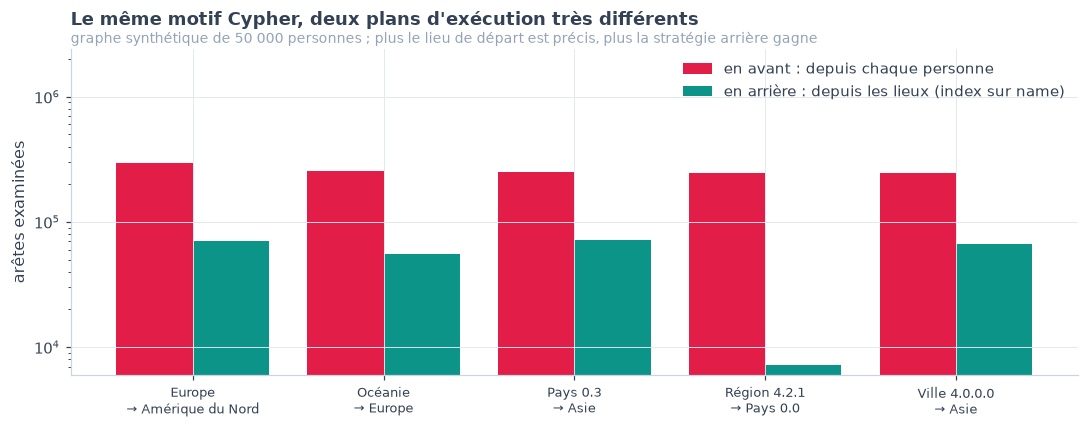

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(strat))
ax.bar(x - 0.2, strat["arêtes, en avant"], 0.4, color=ROSE, label="en avant : depuis chaque personne")
ax.bar(x + 0.2, strat["arêtes, en arrière"], 0.4, color=TEAL, label="en arrière : depuis les lieux (index sur name)")
ax.set_yscale("log")
ax.set_xticks(x, [f"{b}\n→ {l}" for b, l in zip(strat["né(e) à"], strat["vit à"])], fontsize=8.5)
ax.set_ylabel("arêtes examinées")
ax.set_ylim(top=strat["arêtes, en avant"].max() * 8)
ax.set_title("Le même motif Cypher, deux plans d'exécution très différents")
subtitle(ax, "graphe synthétique de 50 000 personnes ; plus le lieu de départ est précis, plus la stratégie arrière gagne")
ax.legend(); plt.tight_layout(); plt.show()

La stratégie « en avant » examine toujours à peu près le même nombre d'arêtes (toutes
les personnes, tous leurs lieux) : son coût ne dépend pas de la question. La stratégie
« en arrière » ne visite que la partie du graphe sous les deux lieux demandés : elle est
d'autant plus rapide que ces lieux sont **sélectifs** (une ville plutôt qu'un continent).
C'est exactement le genre de décision qu'un optimiseur prend à partir de statistiques ;
l'auteur de la requête n'a pas à s'en soucier.

> **À retenir.** Cypher décrit des **motifs** avec une notation en flèches ;
> `-[:WITHIN*0..]->` exprime un chemin de longueur variable. Le langage étant déclaratif,
> le moteur choisit la stratégie de parcours, dont le coût peut varier de plusieurs
> ordres de grandeur.